<center>
<img src="https://storage.googleapis.com/adonaivera_certified/banner.png">
    
##  Diplomado en Ciencia de Datos - Cohorte 2024

Autor: [Juan Felipe Contreras](https://www.linkedin.com/in/juanf-contreras/)

<h1 align='center'> Matriz de Confusión </h1>

Supongona un proyecto en el que se pretende clasificar automáticamente un correo electrónico en una de tres clases: Spam, correo de trabajo, correo personal. Después de entrenar el modelo, se prueba con un conjunto de datos de prueba que contiene 100 correos electrónicos. A continuación se presenta la matriz de confusión del modelo:

|               | Spam (Predicho) | Trabajo (Predicho) | Personal (Predicho) |
|---------------|------------------|---------------------|---------------------|
| Spam (Real)   | 25               | 2                   | 3                   |
| Trabajo (Real)| 1                | 30                  | 0                   |
| Personal (Real)| 3                | 1                   | 35                  |

Para identificar en esta matriz los verdaderos positivos (VP), verdaderos negativos (VN), falsos positivos (FP) y falsos negativos (FN) primero hay que seleccionar una de las tres categorías como positiva, es decir, debemos de fijarla como referencia para analizar las entradas de la matriz. Desglosemos el ejercicio para cada una de las tres categorías:

**Categoría de referencia: SPAM**

En esta matriz:

- Los Verdaderos Positivos (VP) son los correos electrónicos que realmente son spam y que el modelo predijo correctamente como spam. En este caso, serían los correos electrónicos en la casilla "Spam (Real)" e "Spam (Predicho)", que son 25.

- Los Falsos Positivos (FP) son los correos electrónicos que el modelo predijo incorrectamente como spam cuando en realidad no lo son. Estos son los correos electrónicos que están en la columna "Spam (Predicho)" pero no en la fila "Spam (Real)". Aquí, serían los correos electrónicos que fueron predichos como spam pero que en realidad eran de trabajo o personales, sumando 1 + 3 = 4.

- Los Verdaderos Negativos (VN) son los correos electrónicos que el modelo predijo correctamente como no spam. Estos son los correos electrónicos que no están en la fila "Spam (Real)" ni en la columna "Spam (Predicho)". En esta matriz, incluirían todos los correos electrónicos de trabajo y personales que fueron clasificados correctamente, que suman 30 (Trabajo) + 36 (Personal) = 66.

- Los Falsos Negativos (FN) son los correos electrónicos que son spam pero el modelo predijo incorrectamente como no spam. Estos son los correos electrónicos que están en la fila "Spam (Real)" pero no en la columna "Spam (Predicho)". Aquí, serían los correos electrónicos que fueron etiquetados como trabajo o personal pero que en realidad eran spam, sumando 2 + 3 = 5.

Cuándo fijamos la categoría de referencia como Spam, podemos definir los valores anteriores según las siguientes posiciones

|               | Spam (Predicho) | Trabajo (Predicho) | Personal (Predicho) |
|---------------|------------------|---------------------|---------------------|
| Spam (Real)   | VP               | FN                   | FN                   |
| Trabajo (Real)| FP                | VN                  | VN                   |
| Personal (Real)| FP                | VN                   | VN                  |

**Categoría de referencia: Trabajo**

- Los Verdaderos Positivos (VP) son los correos electrónicos que realmente son de trabajo y que el modelo predijo correctamente como trabajo. En este caso, serían los correos electrónicos en la casilla "Trabajo (Real)" y "Trabajo (Predicho)", que son 30.

- Los Falsos Positivos (FP) son los correos electrónicos que el modelo predijo incorrectamente como trabajo cuando en realidad no lo son. Estos son los correos electrónicos que están en la columna "Trabajo (Predicho)" pero no en la fila "Trabajo (Real)". Aquí, serían los correos electrónicos que fueron predichos como trabajo pero que en realidad eran de spam o personales, sumando 2 + 1 = 3.

- Los Verdaderos Negativos (VN) son los correos electrónicos que el modelo predijo correctamente como no spam. Estos son los correos electrónicos que no están en la fila "Spam (Real)" ni en la columna "Spam (Predicho)". En esta matriz, incluirían todos los correos electrónicos de trabajo y personales que fueron clasificados correctamente, que suman 28 (Spam) + 38 (Personal) = 66.

- Los Falsos Negativos (FN) son los correos electrónicos que son trabajo pero el modelo predijo incorrectamente como no trabajo. Estos son los correos electrónicos que están en la fila "Trabajo (Real)" pero no en la columna "Trabajo (Predicho)". Aquí, serían los correos electrónicos que fueron etiquetados como span o personal pero que en realidad eran trabajo, esto es 1 (Spam).

Cuándo fijamos la categoría de referencia como Trabajo, podemos definir los valores anteriores según las siguientes posiciones

|               | Spam (Predicho) | Trabajo (Predicho) | Personal (Predicho) |
|---------------|------------------|---------------------|---------------------|
| Spam (Real)   | VN               | FP                   | VN                   |
| Trabajo (Real)| FN                | VP                  | FN                   |
| Personal (Real)| VN                | FP                   | VN                  |

<h2> Tarea: realizar el análisis anterior para la categoría de referencia "Personal (Real)" </h2>

<h2> Definición matemática </h2>

Sea $C$ una matriz de confusión $K \text{x} K$ tal que $c_{ij}$ es el número de observaciones que pertenecen a la categoría $i$ y el modelo clasificó en la categoría $j$, para una categoría de referencia $k$, tenemos las siguientes definiciones:

**Verdaderos Positivos:**

$$VP = c_{kk}$$

**Falsos Positivos:**

$$FP = \sum_{i \neq k}^{K} c_{ik}$$

**Verdaderos Negativos:**

$$VN = \sum_{i \neq k}^{K} \sum_{j \neq k}^{K} c_{ij}$$

**Falsos Negativos:**

$$FN = \sum_{j \neq k}^{K} c_{kj}$$

<h2> Curva ROC y AUC </h2>

La matriz de confusión describe a un clasificador **con un umbral de decisión fijo**. Casi todos los modelos producen primero un puntaje o probabilidad $s(x)$ y luego predicen la clase positiva si $s(x) > t$ (por defecto $t=0.5$). Si cambiamos $t$, cambia la matriz de confusión completa: un umbral bajo detecta más positivos (más VP, pero también más FP) y un umbral alto es más conservador (menos FP, pero más FN).

La **curva ROC** (*Receiver Operating Characteristic*) resume el comportamiento del modelo para **todos los umbrales a la vez**. Para cada $t$ se calculan dos tasas a partir de la matriz de confusión (con una categoría de referencia positiva):

$$TPR(t) = \frac{VP}{VP+FN} \quad (\text{tasa de verdaderos positivos, sensibilidad o recall})$$

$$FPR(t) = \frac{FP}{FP+VN} \quad (\text{tasa de falsos positivos} = 1-\text{especificidad})$$

y se dibuja el punto $(FPR(t),\,TPR(t))$. Al recorrer $t$ de $+\infty$ a $-\infty$ la curva va desde $(0,0)$ (nada es positivo) hasta $(1,1)$ (todo es positivo).

- La diagonal $TPR=FPR$ corresponde a un clasificador aleatorio.
- Un clasificador perfecto pasa por la esquina $(0,1)$.
- Cuanto más "arriba y a la izquierda" está la curva, mejor separa el modelo las dos clases.

<h3> AUC: área bajo la curva </h3>

El **AUC** (*Area Under the Curve*) resume la curva en un solo número entre 0 y 1:

$$AUC = \int_0^1 TPR\; d(FPR)$$

| AUC | Interpretación |
|---|---|
| 0.5 | El modelo no discrimina mejor que el azar |
| 0.7 – 0.8 | Discriminación aceptable |
| 0.8 – 0.9 | Buena |
| > 0.9 | Excelente (verifica que no haya fuga de datos) |
| < 0.5 | El modelo está invertido (sus puntajes ordenan al revés) |

Tiene una interpretación probabilística muy útil: el AUC es la **probabilidad de que el modelo asigne un puntaje mayor a un positivo elegido al azar que a un negativo elegido al azar**:

$$AUC = P\big(s(X^+) > s(X^-)\big) + \tfrac{1}{2}P\big(s(X^+) = s(X^-)\big)$$

Es decir, mide la calidad del **ordenamiento (ranking)** de los casos, no la de las predicciones con un umbral concreto.

**Propiedades**

- No depende del umbral: evalúa el puntaje, no la decisión final.
- Es invariante a transformaciones monótonas crecientes del puntaje. Por eso no exige probabilidades calibradas: sirve igual para $\hat p$, para $\log$-odds o para la distancia al hiperplano de un SVM.
- Permite **comparar modelos** con puntajes en escalas distintas (regresión logística, KNN, SVM...).

**Limitaciones**

- No dice qué umbral usar ni cuál es el costo de cada error. Para elegir el umbral se puede, por ejemplo, maximizar el **índice de Youden** $J = TPR - FPR$, o minimizar un costo esperado.
- Con **clases muy desbalanceadas** puede dar una imagen optimista: el $FPR$ se calcula sobre una clase negativa enorme, así que miles de falsos positivos apenas lo mueven. En esos casos conviene complementarla con la curva precisión-recall (ver `12_Desbalanceo_Clases.ipynb`).
- Dos curvas pueden tener el mismo AUC y comportarse distinto en la zona que le importa a tu problema (por ejemplo, con FPR muy bajo).

<h3> Extensión a más de dos clases </h3>

La curva ROC se define para un problema binario. Con $K$ categorías, como en el ejemplo de correos (spam, trabajo, personal), se usa la misma idea de **categoría de referencia** de las secciones anteriores:

- **Uno contra el resto (OvR):** para cada categoría $k$ se toma como positiva y las demás como negativas, y se calcula una curva ROC y un AUC por categoría.
- **Uno contra uno (OvO):** se calcula el AUC para cada par de categorías.

Los $K$ valores se promedian: **macro** (promedio simple, trata igual a todas las categorías) o **ponderado** por el número de observaciones de cada categoría.

<h3> Ejemplo en código </h3>

Usamos el conjunto de datos de cáncer de mama (clase positiva = tumor maligno) y una regresión logística. Primero vemos cómo cambia la matriz de confusión con el umbral y luego dibujamos la curva ROC.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy matplotlib scikit-learn

/home/juanf/Projects/Material-Ciencia-de-Datos/.venv/bin/python3: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, RocCurveDisplay

import warnings

warnings.filterwarnings('ignore')

In [3]:
data = load_breast_cancer()
X, y = data.data, (data.target == 0).astype(int)   # 1 = maligno (clase positiva)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
p = logit.predict_proba(X_test)[:, 1]   # puntaje: probabilidad de ser maligno

for t in [0.1, 0.5, 0.9]:
    vn, fp, fn, vp = confusion_matrix(y_test, p > t).ravel()
    print(f'Umbral {t}:  VP={vp:3d}  FP={fp:3d}  FN={fn:3d}  VN={vn:3d}  |  TPR={vp / (vp + fn):.3f}  FPR={fp / (fp + vn):.3f}')

Umbral 0.1:  VP= 63  FP=  7  FN=  1  VN=100  |  TPR=0.984  FPR=0.065
Umbral 0.5:  VP= 60  FP=  1  FN=  4  VN=106  |  TPR=0.938  FPR=0.009
Umbral 0.9:  VP= 51  FP=  0  FN= 13  VN=107  |  TPR=0.797  FPR=0.000


Cada umbral produce una matriz distinta y, por lo tanto, un punto $(FPR, TPR)$ distinto. La curva ROC los recorre todos.

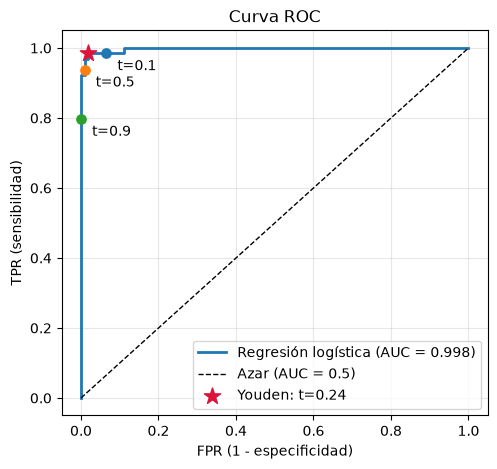

In [4]:
fpr, tpr, umbrales = roc_curve(y_test, p)
auc = roc_auc_score(y_test, p)

# Umbral que maximiza el índice de Youden J = TPR - FPR
i = np.argmax(tpr - fpr)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, lw=2, label=f'Regresión logística (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar (AUC = 0.5)')
for t in [0.1, 0.5, 0.9]:
    vn, fp, fn, vp = confusion_matrix(y_test, p > t).ravel()
    ax.scatter(fp / (fp + vn), vp / (vp + fn), s=45, zorder=3)
    ax.annotate(f't={t}', (fp / (fp + vn), vp / (vp + fn)), textcoords='offset points', xytext=(8, -12))
ax.scatter(fpr[i], tpr[i], marker='*', s=150, c='crimson', zorder=4, label=f'Youden: t={umbrales[i]:.2f}')
ax.set_xlabel('FPR (1 - especificidad)'); ax.set_ylabel('TPR (sensibilidad)')
ax.set_title('Curva ROC'); ax.legend(loc='lower right'); ax.grid(alpha=.3)
plt.show()

**Verificación de la interpretación probabilística.** El AUC debe coincidir con la fracción de pares (positivo, negativo) en los que el positivo recibe mayor puntaje.

In [5]:
pos, neg = p[y_test == 1], p[y_test == 0]
comparaciones = pos[:, None] - neg[None, :]
auc_pares = (comparaciones > 0).mean() + 0.5 * (comparaciones == 0).mean()
print(f'AUC con roc_auc_score: {auc:.4f}   |   AUC como fracción de pares bien ordenados: {auc_pares:.4f}')

AUC con roc_auc_score: 0.9975   |   AUC como fracción de pares bien ordenados: 0.9975


<h3> Comparación de modelos con la curva ROC </h3>

Como el AUC no depende de la escala del puntaje, podemos comparar modelos distintos en la misma gráfica.

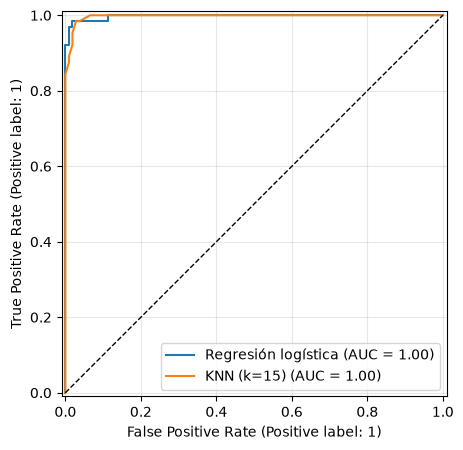

In [6]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_estimator(logit, X_test, y_test, name='Regresión logística', ax=ax)
RocCurveDisplay.from_estimator(knn, X_test, y_test, name='KNN (k=15)', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.grid(alpha=.3); plt.show()

<h3> ROC-AUC multiclase </h3>

Con el conjunto Iris (3 clases) calculamos el AUC en las modalidades uno contra el resto (OvR) y uno contra uno (OvO). El AUC de cada categoría equivale a tomarla como categoría de referencia, como hicimos con la matriz de confusión.

In [7]:
Xi, yi = load_iris(return_X_y=True)
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=42)
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xi_train, yi_train)
P = modelo.predict_proba(Xi_test)

print('OvR macro      :', round(roc_auc_score(yi_test, P, multi_class='ovr', average='macro'), 4))
print('OvR ponderado  :', round(roc_auc_score(yi_test, P, multi_class='ovr', average='weighted'), 4))
print('OvO macro      :', round(roc_auc_score(yi_test, P, multi_class='ovo', average='macro'), 4))

# AUC por categoría de referencia (uno contra el resto)
for k, nombre in enumerate(load_iris().target_names):
    print(f'AUC {nombre:11s}:', round(roc_auc_score(yi_test == k, P[:, k]), 4))

OvR macro      : 0.9956
OvR ponderado  : 0.9956
OvO macro      : 0.9956
AUC setosa     : 1.0
AUC versicolor : 0.9933
AUC virginica  : 0.9933
